In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings

from imblearn.over_sampling import SMOTE

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)

import lightgbm as lgb
import mlflow
import pickle

warnings.filterwarnings("ignore")

Peeking the dataset

In [2]:
df = pd.read_csv(r"D:\projVehicleInsurance\vehicle-Insurance\notebooks\data.csv")
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


Lets do some EDA

In [3]:
df.shape

(381109, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [5]:
df.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


In [6]:
df.isnull().sum()

id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

Response
0    334399
1     46710
Name: count, dtype: int64

Imbalance ratio  (0:1) = 7.16x


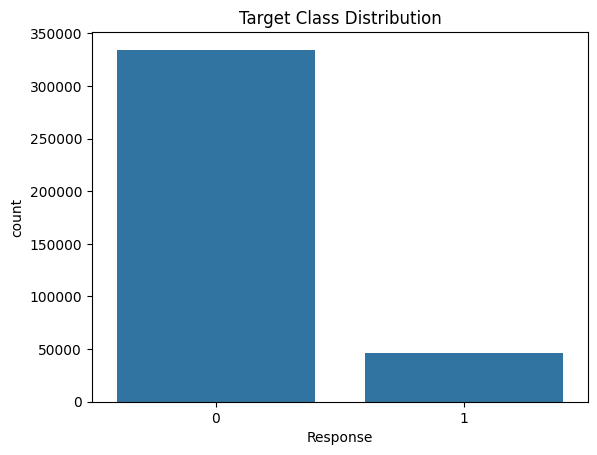

In [8]:
#how the classes are distributed in the target variable
response_counts = df["Response"].value_counts()
print(response_counts)
print(f"\nImbalance ratio  (0:1) = {response_counts[0] / response_counts[1]:.2f}x")

sns.countplot(x="Response", data=df)
plt.title("Target Class Distribution")
plt.show()

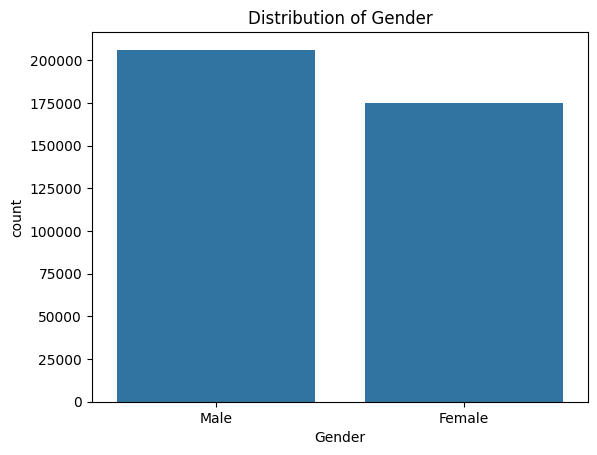

In [9]:
# Gender distribution
sns.countplot(x="Gender", data=df)
plt.title("Distribution of Gender")
plt.show()

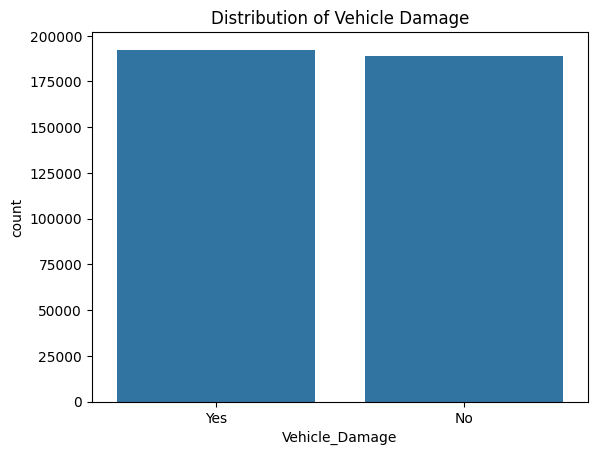

In [9]:
# Vehicle damage distribution
sns.countplot(x="Vehicle_Damage", data=df)
plt.title("Distribution of Vehicle Damage")
plt.show()

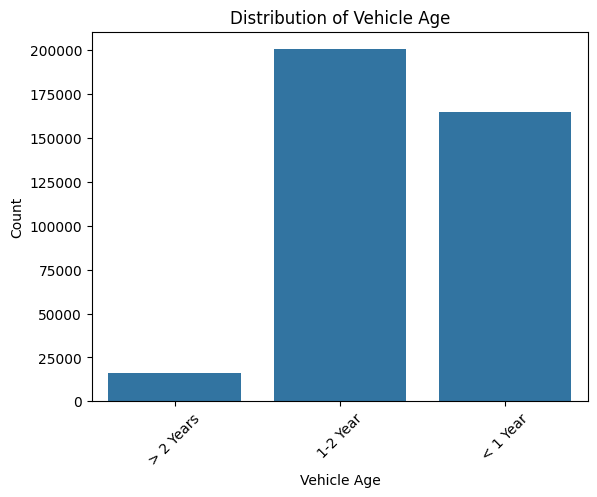

In [11]:
# Vehicle age distribution
sns.countplot(x="Vehicle_Age", data=df)
plt.xlabel("Vehicle Age")
plt.ylabel("Count")
plt.title("Distribution of Vehicle Age")
plt.xticks(rotation=45)
plt.show()

In [11]:
# Response vs Vehicle Age
data = (
    df.groupby(["Vehicle_Age", "Response"])["id"]
    .count()
    .to_frame()
    .rename(columns={"id": "count"})
    .reset_index()
)
data

,Vehicle_Age,Response,count
0,1-2 Year,0,165510
1,1-2 Year,1,34806
2,< 1 Year,0,157584
3,< 1 Year,1,7202
4,> 2 Years,0,11305
5,> 2 Years,1,4702


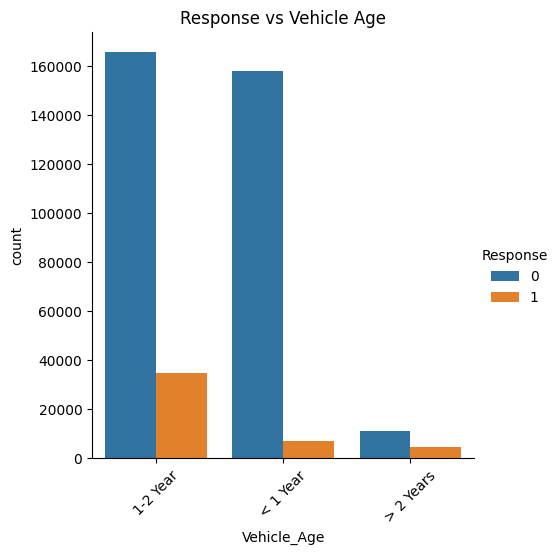

In [12]:
sns.catplot(
    x="Vehicle_Age",
    y="count",
    hue="Response",
    data=data,
    kind="bar",
)
plt.title("Response vs Vehicle Age")
plt.xticks(rotation=45)
plt.show()

### data preprocessing
enough of eda now lets do some data preprocessing before we move to modelling. We will do some feature engineering and then we will do some encoding of categorical variables and then we will do some scaling of numerical variables. After that we will split the data into train and test sets and then we will do some modelling.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [14]:
X = df.drop(["id", "Response"], axis=1)
y = df["Response"]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train shape : {X_train.shape}")
print(f"Test shape  : {X_test.shape}")
print(f"\nTrain class distribution:\n{y_train.value_counts()}")
print(f"\nTest class distribution:\n{y_test.value_counts()}")

Train shape : (304887, 10)
Test shape  : (76222, 10)

Train class distribution:
Response
0    267519
1     37368
Name: count, dtype: int64

Test class distribution:
Response
0    66880
1     9342
Name: count, dtype: int64


In [16]:
X_train.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage
274710,Male,22,1,40.0,0,< 1 Year,Yes,25455.0,152.0,203
216539,Female,26,1,8.0,1,< 1 Year,No,38393.0,26.0,45
78983,Female,32,1,28.0,0,< 1 Year,Yes,32118.0,122.0,35
218368,Male,32,1,37.0,0,< 1 Year,Yes,37711.0,152.0,215
307215,Female,24,1,28.0,0,< 1 Year,Yes,48706.0,156.0,222


In [17]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

In [18]:
X_train.head()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Gender_Male,Vehicle_Age_< 1 Year,Vehicle_Age_> 2 Years,Vehicle_Damage_Yes
274710,22,1,40.0,0,25455.0,152.0,203,True,True,False,True
216539,26,1,8.0,1,38393.0,26.0,45,False,True,False,False
78983,32,1,28.0,0,32118.0,122.0,35,False,True,False,True
218368,32,1,37.0,0,37711.0,152.0,215,True,True,False,True
307215,24,1,28.0,0,48706.0,156.0,222,False,True,False,True


In [19]:
# both train and test have same columns after one hot encoding
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

In [20]:
X_train.columns = (
    X_train.columns.str.replace("<", "lessthan", regex=False)
    .str.replace(">", "greaterthan", regex=False)
    .str.replace(" ", "_", regex=False)
)
X_test.columns = (
    X_test.columns.str.replace("<", "lessthan", regex=False)
    .str.replace(">", "greaterthan", regex=False)
    .str.replace(" ", "_", regex=False)
)

In [21]:
X_train.head()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Gender_Male,Vehicle_Age_lessthan_1_Year,Vehicle_Age_greaterthan_2_Years,Vehicle_Damage_Yes
274710,22,1,40.0,0,25455.0,152.0,203,True,True,False,True
216539,26,1,8.0,1,38393.0,26.0,45,False,True,False,False
78983,32,1,28.0,0,32118.0,122.0,35,False,True,False,True
218368,32,1,37.0,0,37711.0,152.0,215,True,True,False,True
307215,24,1,28.0,0,48706.0,156.0,222,False,True,False,True


In [22]:
num_cols = ["Age", "Annual_Premium", "Vintage"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [23]:
X_train.head()

,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Gender_Male,Vehicle_Age_lessthan_1_Year,Vehicle_Age_greaterthan_2_Years,Vehicle_Damage_Yes
274710,-1.084538,1,40.0,0,-0.297943,152.0,0.580945,True,True,False,True
216539,-0.826727,1,8.0,1,0.452554,26.0,-1.307422,False,True,False,False
78983,-0.440011,1,28.0,0,0.088559,122.0,-1.426939,False,True,False,True
218368,-0.440011,1,37.0,0,0.412993,152.0,0.724365,True,True,False,True
307215,-0.955632,1,28.0,0,1.050781,156.0,0.808027,False,True,False,True


### Metric Logger for MLflow
Need to build a single function which will log the metrics to MLflow.

In [24]:
def metric_logger(model_name, best_params, y_test, y_pred, y_proba):
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    mlflow.log_params(best_params)
    mlflow.log_metric("test_accuracy", acc)
    mlflow.log_metric("test_precision", precision)
    mlflow.log_metric("test_recall", recall)
    mlflow.log_metric("test_f1_score", f1)
    mlflow.log_metric("test_roc_auc", roc_auc)

    print(f"Model:{model_name}")
    print(f"Best params : {best_params}")
    print(f"{'-' * 10}")
    print(f"Accuray : {acc:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")
    print(f"{'-' * 10}")
    print(classification_report(y_test, y_pred, zero_division=0))
    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
    }

In [46]:
import mlflow.sklearn

Since we know that our dataset is imbalanced, we will use the following metrics to evaluate our model:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC Score



Also lets start with tracking our models for Imbalance dataset using MLflow. Then we will later use SMOTE and other techniques to handle the imbalance and then we will compare the results.

In [27]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Vehicle_Insurance_Round1_Imbalanced")
mlflow.sklearn.autolog(disable=True)

In [25]:
experiments_round1 = {
    "LogisticRegression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {
            "C": [0.01, 0.1, 1, 10, 100],
            "class_weight": [None, "balanced"],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [None, 5, 10, 15],
            "min_samples_split": [2, 5, 10],
            "class_weight": [None, "balanced"],
        },
    ),
    "LightGBM": (
        lgb.LGBMClassifier(random_state=42, n_jobs=-1),
        {
            "learning_rate": [0.01, 0.05, 0.1],
            "n_estimators": [100, 200, 300],
            "max_depth": [3, 5, 7],
            "class_weight": [None, "balanced"],
        },
    ),
}

In [28]:
round1_results = {}
round1_models = {}

for model_name, (clf, param_grid) in experiments_round1.items():
    print(f"\n--- Starting with {model_name} ---")

    with mlflow.start_run(run_name=f"Imbalanced_{model_name}"):
        mlflow.set_tag("round", "1_imbalanced")
        mlflow.set_tag("model", model_name)

        search = RandomizedSearchCV(
            estimator=clf,
            param_distributions=param_grid,
            n_iter=10,
            cv=3,
            scoring="roc_auc",
            random_state=42,
            n_jobs=-1,
        )
        search.fit(X_train, y_train)

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)[:, 1]

        metrics = metric_logger(
            model_name, search.best_params_, y_test, y_pred, y_proba
        )
        round1_results[model_name] = metrics
        round1_models[model_name] = {"model": best_model, "best_params": search.best_params_}
        mlflow.sklearn.log_model(best_model, artifact_path=f"{model_name}_model")

print("\n Round 1 Done.")


--- Starting with LogisticRegression ---


2026/03/27 14:31:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model:LogisticRegression
Best params : {'class_weight': None, 'C': 10}
----------
Accuray : 0.8774
Precision : 0.5000
Recall: 0.0001
F1 Score: 0.0002
ROC AUC: 0.8385
----------
              precision    recall  f1-score   support

           0       0.88      1.00      0.93     66880
           1       0.50      0.00      0.00      9342

    accuracy                           0.88     76222
   macro avg       0.69      0.50      0.47     76222
weighted avg       0.83      0.88      0.82     76222



2026/03/27 14:31:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/27 14:32:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run Imbalanced_LogisticRegression at: http://127.0.0.1:5000/#/experiments/2/runs/bc86832970f44a2e930d001c4327c3a8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

--- Starting with RandomForest ---


...

🏃 View run Imbalanced_RandomForest at: http://127.0.0.1:5000/#/experiments/2/runs/eb246ef403ab4a5c8b388c09a36661e7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

--- Starting with LightGBM ---
[LightGBM] [Info] Number of positive: 37368, number of negative: 267519
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014728 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 769
[LightGBM] [Info] Number of data points in the train set: 304887, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.122563 -> initscore=-1.968376
[LightGBM] [Info] Start training from score -1.968376
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM

2026/03/27 14:53:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model:LightGBM
Best params : {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'class_weight': None}
----------
Accuray : 0.8775
Precision : 0.5455
Recall: 0.0019
F1 Score: 0.0038
ROC AUC: 0.8575
----------
              precision    recall  f1-score   support

           0       0.88      1.00      0.93     66880
           1       0.55      0.00      0.00      9342

    accuracy                           0.88     76222
   macro avg       0.71      0.50      0.47     76222
weighted avg       0.84      0.88      0.82     76222



2026/03/27 14:53:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/03/27 14:54:13 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run Imbalanced_LightGBM at: http://127.0.0.1:5000/#/experiments/2/runs/201fefe0d8474de4b565025ce525407e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

 Round 1 Done.


As expected, the model is performing poorly on the minority class (Response=1) due to the imbalance in the dataset. The accuracy is high, but the precision, recall, and F1 score for the minority class are very low. The model is not able to correctly identify the response=1 cases since they are low in number compared to response=0 cases. Thus we need to handle the data imbalance

SMOTE Oversampling

In [29]:
print(f"Before SMOTE — X_train shape : {X_train.shape}")
print(f"Before SMOTE — y_train distribution:\n{y_train.value_counts()}")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"\nAfter SMOTE  — X_train shape : {X_train_smote.shape}")
print(
    f"After SMOTE  — y_train distribution:\n{pd.Series(y_train_smote).value_counts()}"
)


Before SMOTE — X_train shape : (304887, 11)
Before SMOTE — y_train distribution:
Response
0    267519
1     37368
Name: count, dtype: int64

After SMOTE  — X_train shape : (535038, 11)
After SMOTE  — y_train distribution:
Response
0    267519
1    267519
Name: count, dtype: int64


In [30]:
mlflow.set_experiment("Vehicle_Insurance_Round2_SMOTE")

<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1774585082145, experiment_id='3', last_update_time=1774585082145, lifecycle_stage='active', name='Vehicle_Insurance_Round2_SMOTE', tags={}, workspace='default'>

In [ ]:
experiments_round2 = {
    "LogisticRegression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {
            "C": [0.001, 0.01, 0.1, 1, 10, 100],
            "solver": ["lbfgs", "liblinear"],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "n_estimators": [100, 200,300],          
            "max_depth": [10, 15, 20],            
            "min_samples_split": [5, 10],        
            "min_samples_leaf": [2, 4],          
            "max_features": ["sqrt", "log2"],
        },
    ),
    "LightGBM": (
        lgb.LGBMClassifier(random_state=42, n_jobs=-1),
        {
            "learning_rate": [0.01, 0.05, 0.1, 0.2],
            "n_estimators": [100, 200, 300, 500],
            "max_depth": [3, 5, 7, 10],
            "num_leaves": [31, 63, 127],
            "min_child_samples": [20, 50, 100],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0],
        },
    ),
}

In [32]:
round2_results = {}
round2_models = {}

for model_name, (clf, param_grid) in experiments_round2.items():
    print(f"\n Starting Round 2 (SMOTE) | {model_name}")

    with mlflow.start_run(run_name=f"Round2_SMOTE_{model_name}"):
        mlflow.set_tag("round", "2_smote")
        mlflow.set_tag("model", model_name)
        mlflow.set_tag("sampling", "SMOTE")

        search = RandomizedSearchCV(
            estimator=clf,
            param_distributions=param_grid,
            n_iter=15,
            cv=3,
            scoring="f1",
            random_state=42,
            n_jobs=-1,
        )
        search.fit(X_train_smote, y_train_smote)

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)[:, 1]

        metrics = metric_logger(
            model_name, search.best_params_, y_test, y_pred, y_proba
        )
        round2_results[model_name] = metrics
        round2_models[model_name] = {
            "model": best_model,
            "best_params": search.best_params_,
            "round_label": "Round2_SMOTE",
            "sampling": "SMOTE",
        }

print("\n Round 2 complete.")


 Starting Round 2 (SMOTE) | LogisticRegression
Model:LogisticRegression
Best params : {'solver': 'lbfgs', 'C': 0.001}
----------
Accuray : 0.6404
Precision : 0.2509
Recall: 0.9736
F1 Score: 0.3989
ROC AUC: 0.8378
----------
              precision    recall  f1-score   support

           0       0.99      0.59      0.74     66880
           1       0.25      0.97      0.40      9342

    accuracy                           0.64     76222
   macro avg       0.62      0.78      0.57     76222
weighted avg       0.90      0.64      0.70     76222

🏃 View run Round2_SMOTE_LogisticRegression at: http://127.0.0.1:5000/#/experiments/3/runs/8cb9f789c1994c1381951f6021e1cf7f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

 Starting Round 2 (SMOTE) | RandomForest
Model:RandomForest
Best params : {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 20}
----------
Accuray : 0.7465
Precision : 0.3044
Recall: 0.8314
F1 Score: 0.4457
R

Far better results after applying SMOTE. The model is now able to correctly identify the response=1 cases and the precision, recall, and F1 score for the minority class have improved significantly. The accuracy has also improved but it is not the best metric to evaluate the model in this case due to the imbalance in the dataset. The ROC AUC score has also improved which indicates that the model is better at distinguishing between the two classes.
The main metric for insurance companies is recall, as they want to identify as many potential claimants as possible. The precision is also important as it indicates how many of the identified claimants are actually going to claim. The F1 score is a good metric to evaluate the model as it takes into account both precision and recall. The ROC AUC score is also important as it indicates how well the model is able to distinguish between the two classes.

Round 3  -  class weight balanced , no resampling
This is a simpler strategy which i am using since smote increases the samples very much and already our dataset is big.
This penalise misclassification of the minority class proportionally to its frequency.  

Also one more thing LightGBM uses `is_unbalance=True` OR `scale_pos_weight` as it doesnt have class_wights = none or balanced parameter. 

In [ ]:
mlflow.set_experiment("Vehicle_Insurance_Round3_ClassWeight")

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = round(neg_count / pos_count, 4)
print(f"scale_pos_weight for LightGBM: {scale_pos_weight_val}")

2026/03/27 16:17:24 INFO mlflow.tracking.fluent: Experiment with name 'Vehicle_Insurance_Round3_ClassWeight' does not exist. Creating a new experiment.


scale_pos_weight for LightGBM: 7.159


In [ ]:
experiments_round3 = {
    "LogisticRegression": (
        LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
        {
            "C": [0.001, 0.01, 0.1, 1, 10, 100],
            "solver": ["lbfgs", "liblinear"],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42, n_jobs=-1, class_weight="balanced"),
        {
            "n_estimators": [100, 200],
            "max_depth": [10, 15, 20],          
            "min_samples_split": [5, 10],
            "min_samples_leaf": [2, 4],
            "max_features": ["sqrt", "log2"],
        },
    ),
    
    #tesing both the strategies
    "LightGBM_is_unbalance": (
        lgb.LGBMClassifier(random_state=42, n_jobs=-1, is_unbalance=True),
        {
            "learning_rate": [0.01, 0.05, 0.1, 0.2],
            "n_estimators": [100, 200, 300, 500],
            "max_depth": [3, 5, 7, 10],
            "num_leaves": [31, 63, 127],
            "min_child_samples": [20, 50, 100],
        },
    ),
    "LightGBM_scale_pos_weight": (
        lgb.LGBMClassifier(
            random_state=42, n_jobs=-1,
            scale_pos_weight=scale_pos_weight_val
        ),
        {
            "learning_rate": [0.01, 0.05, 0.1, 0.2],
            "n_estimators": [100, 200, 300, 500],
            "max_depth": [3, 5, 7, 10],
            "num_leaves": [31, 63, 127],
            "min_child_samples": [20, 50, 100],
        },
    ),
}

In [ ]:
round3_results = {}
round3_models = {}

for model_name, (clf, param_grid) in experiments_round3.items():
    print(f"\n Starting Round 3 (ClassWeight) | {model_name}")

    with mlflow.start_run(run_name=f"Round3_CW_{model_name}"):
        mlflow.set_tag("round", "3_class_weight")
        mlflow.set_tag("model", model_name)
        mlflow.set_tag("sampling", "class_weight_balanced")

        search = RandomizedSearchCV(
            estimator=clf,
            param_distributions=param_grid,
            n_iter=15,
            cv=3,
            scoring="f1",
            random_state=42,
            n_jobs=-1,
        )
        search.fit(X_train, y_train)  

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)[:, 1]

        metrics = metric_logger(
            model_name, search.best_params_, y_test, y_pred, y_proba
        )
        round3_results[model_name] = metrics
        round3_models[model_name] = {
            "model": best_model,
            "best_params": search.best_params_,
            "round_label": "Round3_ClassWeight",
            "sampling": "class_weight_balanced",
        }

print("\n Round 3 complete.")


 Starting Round 3 (ClassWeight) | LogisticRegression
Model:LogisticRegression
Best params : {'solver': 'liblinear', 'C': 10}
----------
Accuray : 0.6408
Precision : 0.2511
Recall: 0.9740
F1 Score: 0.3993
ROC AUC: 0.8385
----------
              precision    recall  f1-score   support

           0       0.99      0.59      0.74     66880
           1       0.25      0.97      0.40      9342

    accuracy                           0.64     76222
   macro avg       0.62      0.78      0.57     76222
weighted avg       0.90      0.64      0.70     76222

🏃 View run Round3_CW_LogisticRegression at: http://127.0.0.1:5000/#/experiments/4/runs/bea30ba4c5454a969e7b688bd162dab1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4

 Starting Round 3 (ClassWeight) | RandomForest
Model:RandomForest
Best params : {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 20}
----------
Accuray : 0.7528
Precision : 0.3092
Recall: 0.8238
F1 Scor

Lets compare between all models and see which one is the best. We will use the same metrics to evaluate all the models and then we will compare the results.

In [36]:
def results_to_df(results_dict, round_label):
    rows = []
    for model, metrics in results_dict.items():
        rows.append({"Round": round_label, "Model": model, **metrics})
    return pd.DataFrame(rows)

df_r1 = results_to_df(round1_results, "Round1 Imbalanced")
df_r2 = results_to_df(round2_results, "Round2 SMOTE")
df_r3 = results_to_df(round3_results, "Round3 ClassWeight")

comparison_df = (
    pd.concat([df_r1, df_r2, df_r3], ignore_index=True)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

print("\n📊 All Rounds — Sorted by F1 Score\n")
print(comparison_df.to_string(index=False))


📊 All Rounds — Sorted by F1 Score

             Round                     Model  accuracy  precision   recall       f1  roc_auc
Round3 ClassWeight              RandomForest  0.752827   0.309200 0.823806 0.449638 0.852216
      Round2 SMOTE              RandomForest  0.746517   0.304433 0.831407 0.445675 0.850664
Round3 ClassWeight     LightGBM_is_unbalance  0.720881   0.292390 0.899486 0.441322 0.855812
Round3 ClassWeight LightGBM_scale_pos_weight  0.720881   0.292390 0.899486 0.441322 0.855812
Round3 ClassWeight        LogisticRegression  0.640786   0.251104 0.973988 0.399272 0.838516
      Round2 SMOTE        LogisticRegression  0.640432   0.250862 0.973560 0.398930 0.837819
      Round2 SMOTE                  LightGBM  0.838459   0.343780 0.349925 0.346825 0.841334
 Round1 Imbalanced              RandomForest  0.877240   0.432432 0.005138 0.010156 0.855915
 Round1 Imbalanced                  LightGBM  0.877476   0.545455 0.001927 0.003840 0.857486
 Round1 Imbalanced        Logistic

Okay so after seeing all the results, we see that Round3 classweight has best f1 for the minority class and also has good recall but LightGBM with SMOTE has better recall but lower f1 score and very low drop in f1 score and also lightGBM is a lighter and faster model than Random Forest. So we will choose LightGBM with `is_unbalance = True` as our final model.

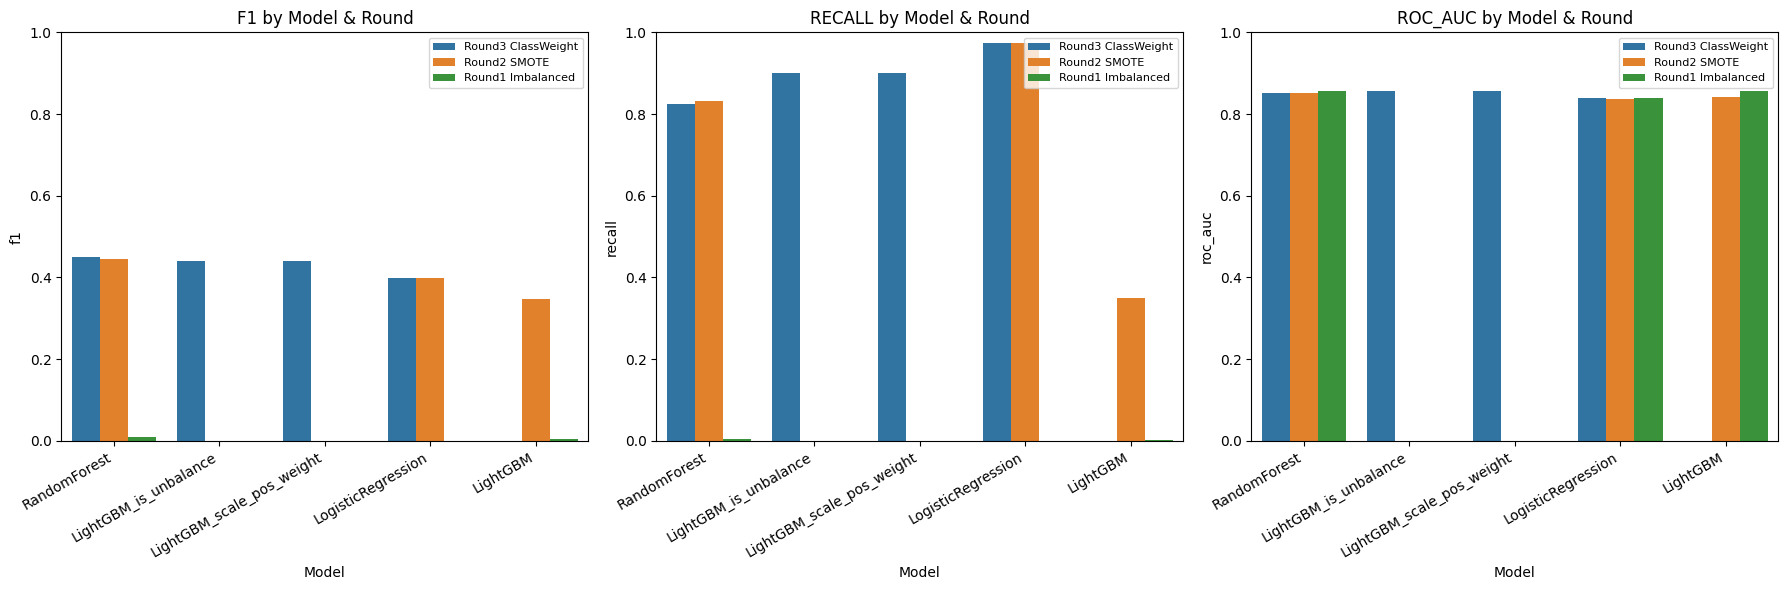

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, metric in zip(axes, ["f1", "recall", "roc_auc"]):
    sns.barplot(data=comparison_df, x="Model", y=metric, hue="Round", ax=ax)
    ax.set_title(f"{metric.upper()} by Model & Round")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("experiment_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

Lets save the winner model.

In [ ]:
import datetime
from datetime import datetime

winner_name  = "LightGBM_is_unbalance"
winner_entry = round3_models[winner_name]
winner_row   = comparison_df[comparison_df["Model"] == winner_name].iloc[0]

print(f" Saving  : {winner_name}")
print(f"   Round   : {winner_entry['round_label']}")
print(f"   Recall  : {winner_row['recall']:.4f}")
print(f"   F1      : {winner_row['f1']:.4f}")
print(f"   ROC AUC : {winner_row['roc_auc']:.4f}")

 Saving  : LightGBM_is_unbalance
   Round   : Round3_ClassWeight
   Recall  : 0.8995
   F1      : 0.4413
   ROC AUC : 0.8558


Apart from saving the model, we also need to save the scaler and the metadata of the model which will be required for inference. 


In [ ]:

artifact_bundle = {
    "model": winner_entry["model"],
    "scaler": scaler,
    "feature_names": list(X_train.columns),
    "num_cols": num_cols,
    "metadata": {
        "model_name":  winner_name,
        "round":       winner_entry["round_label"],
        "sampling":    winner_entry["sampling"],
        "best_params": winner_entry["best_params"],
        "test_metrics": {
            "accuracy":  winner_row["accuracy"],
            "precision": winner_row["precision"],
            "recall":    winner_row["recall"],
            "f1":        winner_row["f1"],
            "roc_auc":   winner_row["roc_auc"],
        },
        "saved_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    },
}

In [ ]:
save_dir = os.path.join("..", "artifacts", "models")
os.makedirs(save_dir, exist_ok=True)

filename  = f"best_model_{winner_entry['round_label']}_{winner_name}.pkl"
save_path = os.path.join(save_dir, filename)

with open(save_path, "wb") as f:
    pickle.dump(artifact_bundle, f)

print(f" Saved to : {save_path}")

 Saved to : ..\artifacts\models\best_model_Round3_ClassWeight_LightGBM_is_unbalance.pkl


Yayy 😁 finally after lot of experimentation and running the code for a long time we have saved our best model now.


Lets just do a quick inference test to see if the model is working fine and then we will be done with this notebook.

In [ ]:
with open(save_path, "rb") as f:
    loaded = pickle.load(f)

print("Reload successful. Keys in bundle:", list(loaded.keys()))
print(f"\n   Model type     : {type(loaded['model'])}")
print(f"   Feature count  : {len(loaded['feature_names'])}")
print(f"   Features       : {loaded['feature_names']}")
print(f"   Num cols       : {loaded['num_cols']}")
print(f"   Metadata       : {loaded['metadata']}")

sample_preds  = loaded["model"].predict(X_test[:5])
sample_probas = loaded["model"].predict_proba(X_test[:5])[:, 1]
print(f"\n   Sample preds   : {sample_preds}")
print(f"   Sample probas  : {sample_probas.round(3)}")

Reload successful. Keys in bundle: ['model', 'scaler', 'feature_names', 'num_cols', 'metadata']

   Model type     : <class 'lightgbm.sklearn.LGBMClassifier'>
   Feature count  : 11
   Features       : ['Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Gender_Male', 'Vehicle_Age_lessthan_1_Year', 'Vehicle_Age_greaterthan_2_Years', 'Vehicle_Damage_Yes']
   Num cols       : ['Age', 'Annual_Premium', 'Vintage']
   Metadata       : {'model_name': 'LightGBM_is_unbalance', 'round': 'Round3_ClassWeight', 'sampling': 'class_weight_balanced', 'best_params': {'num_leaves': 127, 'n_estimators': 300, 'min_child_samples': 50, 'max_depth': 7, 'learning_rate': 0.1}, 'test_metrics': {'accuracy': np.float64(0.7208811104405553), 'precision': np.float64(0.29239013187654406), 'recall': np.float64(0.8994861913937059), 'f1': np.float64(0.4413224442635435), 'roc_auc': np.float64(0.8558122109762567)}, 'saved_at': '2026-03-27 18:29:59'}

   Sam